In [1]:

# Install necessary Python packages for meditation preprocessing
# Run "python3 -m pip install mne scipy numpy matplotlib" in terminal first
# Also run "python3 -m pip install "mne-qt-browser PySide6"
from pathlib import Path

import mne
import numpy as np
from scipy.io import loadmat

# Set up variables
DATA = Path("/Users/emmaabecasis/Downloads/meditation_test_data")
MAT_VARIABLE = None
EEG_CHANNEL_NAMES = [
    "Fp1", "Fp2",
    "FC5", "FC6",
    "Fz", "T7",
    "Cz", "T8",
    "P7", "P3",
    "Pz", "P4",
    "P8", "O1",
    "Oz", "O2",
]

ORIGINAL_REFERENCE = "AFZ"

# Unclear if values are in microvolts or volts (if in volts, scale value should be 1.0)
EEG_SCALE = 1e-6

KNOWN_SFREQ = 512

# Values for bandpass filter
L_FREQ = 0.5
H_FREQ = 41.0

EPOCH_DURATION = 5.0
TARGET_SFREQ = 256

# We should determine the exact cutoffs that are suitable for our data - decide after collection
REJECT_CRITERIA = {"eeg": 150e-6}
FLAT_CRITERIA = {"eeg": 0.5e-6}


In [5]:
# Create functions to read each .mat file
def find_recording_matrix(mat_file):
    if MAT_VARIABLE is not None: 
        matrix = np.asarray(mat_file[MAT_VARIABLE]).squeeze()

        if matrix.ndim != 2:
            raise ValueError(
                f"{MAT_VARIABLE} is not a 2-dimensional matrix"
            )
        return matrix

    candidates = []

    for variable_name, value in mat_file.items():
        if variable_name.startswith("__"):
            continue

        array = np.asarray(value).squeeze()

        if array.ndim == 2 and 19 in array.shape:
            candidates.append((variable_name, array))

    if len(candidates) == 0:
        raise ValueError(
            "No 2-dimensional matrix with 19 in its shape was found"
        )

    if len(candidates) > 1: 
        names = [name for name, _ in candidates]
        raise ValueError(
            f"Multiple 2-dimensional matrices with 19 in their shape were found: {names}"
        )

    variable_name, matrix = candidates[0]
    print(f"Using MATLAB variable: {variable_name}")
    return matrix

# Turn MATLAB matrix into MNE Raw object
def load_participant(mat_path):
    mat_file = loadmat(mat_path)
    matrix = find_recording_matrix(mat_file)

    if matrix.shape[1] != 19 and matrix.shape[0] == 19:
        matrix = matrix.T

    if matrix.shape[1] != 19:
        # Use the notebook's existing DATA path and create an output directory.
        DATA_DIR = DATA
        OUTPUT_DIR = DATA / "processed"
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    timestamps = matrix[:, 0].astype(float) # timestamps listed in first column
    eeg_data = matrix[:, 1:17].astype(float) * EEG_SCALE
    condition_1 = matrix[:, 17].astype(int)
    condition_2 = matrix[:, 18].astype(int)
    sfreq = float(KNOWN_SFREQ)

    channel_names = EEG_CHANNEL_NAMES + ["COND_1", "COND_2"]
    channel_types = ["eeg"] * 16 + ["stim", "stim"]

    # MNE functions expect channels x samples
    mne_data = np.vstack(
        [eeg_data.T,
         condition_1[np.newaxis, :],
         condition_2[np.newaxis, :]]
    )

    info = mne.create_info(
        ch_names=channel_names,
        sfreq=sfreq,
        ch_types=channel_types
    )

    info["description"] = (f"Original acquisition reference: {ORIGINAL_REFERENCE}")

    # Create MNE Raw object!
    raw = mne.io.RawArray(mne_data, info)

    # names and positions follow standard 10-20
    montage = mne.channels.make_standard_montage("standard_1020")
    raw.set_montage(montage, on_missing="raise")

    return raw

# Create condition-block annotations (we may not need to do this, depending on how we structure data)
def add_condition_annotations(raw):
    event_1 = mne.find_events(
        raw, stim_channel="COND_1",  shortest_event=1, verbose=False,
    )

    event_2 = mne.find_events(
        raw, stim_channel="COND_2",  shortest_event=1, verbose=False,
    )

    block_starts = []

    for event in event_1: 
        block_starts.append((event[0], "condition_1"))

    for event in event_2:
        block_starts.append((event[0], "condition_2"))

    block_starts.sort(key=lambda item: item[0])

    if not block_starts:
        raise ValueError("No condition blocks found")

    sfreq = raw.info["sfreq"]
    recording_end = raw.n_times / sfreq

    onsets = []
    durations = []
    descriptions = []

    for index, (sample, condition) in enumerate(block_starts):
        onset = sample / sfreq

        if index + 1 < len(block_starts):
            next_onset = block_starts[index + 1][0] / sfreq
        else:
            next_onset = recording_end

        duration = next_onset - onset

        onsets.append(onset)
        durations.append(duration)
        descriptions.append(condition)

    condition_annotations = mne.Annotations(
        onset=onsets, duration=durations, description=descriptions
    )

    raw.set_annotations(raw.annotations + condition_annotations)

    return raw

# Manually identifying bad channels
# When MNE window displays, click channel name to mark it bad
# Press A to open annotation mode
# Use descriptions starting with "BAD"
# Close window when finished
def mark_bad_data(raw, participant_id):
    raw.plot(
        duration=20,
        n_channels=18,
        scalings="auto",
        block=True
    )

    print("Bad channels:", raw.info["bads"])
    print("Annotations:", raw.annotations)

    return raw

# Filtering and ICA
def filter_and_ica(raw, participant_id):
    filtered = raw.copy()

    # Band-pass filter
    filtered.filter(
        l_freq=L_FREQ,
        h_freq=H_FREQ
    )

    # ICA
    ica = mne.preprocessing.ICA(
        method="infomax",
        fit_params={"extended": True},
        n_components=0.99, # will preserve 99% of variance
        random_state=42, # ensures reproducibility
        max_iter="auto" # automatically determine the maximum number of iterations
    )

    ica.fit(
        filtered,
        picks="eeg",
        reject_by_annotation=True
    )

    ica.plot_components()

#   if response:
#      ica.exclude = [
#            int(component.strip())
#            for component in response.split(",")
#        ]
#    else:
#        ica.exclude = []

    return filtered, ica

# Interpolation and average referencing
def interpolate_and_reference(raw):
    if raw.info["bads"]:
        raw.interpolate_bads(reset_bads=True, method={"eeg": "spline"})

    raw.set_eeg_reference(ref_channels="average", projection=True)

    return raw

# Create 5-sec epochs
def create_epochs(raw):
    events = []
    sfreq = raw.info["sfreq"]

    event_id = {
        "condition_1": 1,
        "condition_2": 2
    }

    for annotation in raw.annotations:
        description = annotation["description"]

        if description not in event_id:
            continue

        block_start = annotation["onset"]
        block_end = block_start + annotation["duration"]

        epoch_start = block_start

        # keep complete 5-sec epochs
        while epoch_start + EPOCH_DURATION <= block_end:
            sample = raw.time_as_index(
                epoch_start,
                use_rounding=True,
            )[0]

            events.append([sample, 0, event_id[description]])

            epoch_start += EPOCH_DURATION

    if not events:
        raise ValueError("No valid epochs found.")

    events = np.asarray(events, dtype=int)
    events = events[np.argsort(events[:, 0])]

    tmax = EPOCH_DURATION - (1 / sfreq)
    epochs = mne.Epochs(
        raw, 
        events,
        event_id=event_id,
        tmin=0,
        tmax=tmax,
        baseline=None,
        detrend=0, # removes constant/mean value from each epoch
        picks="eeg",
        preload=True,
        reject=REJECT_CRITERIA,
        flat=FLAT_CRITERIA,
        reject_by_annotation=True,
        proj=True
    )

    return epochs

# Quality-control output
def inspect_and_save(epochs, raw, participant_id):
    original_epoch_count = len(epochs.events)
    epochs.drop_bad()
    retained_epoch_count = len(epochs)
    rejected_epoch_count = original_epoch_count - retained_epoch_count

    if original_epoch_count:
        rejected_percentage = (100* rejected_epoch_count / original_epoch_count)
    else:
        rejected_percentage = np.nan

    print(f"\n{participant_id} quality summary")
    print(f"Original epochs: {original_epoch_count}")
    print(f"Retained epochs: {retained_epoch_count}")
    print(f"Rejected epochs: {rejected_epoch_count}")
    print(f"Rejected percentage: {rejected_percentage:.1f}%")

    epochs.plot_drop_log()
    epochs.plot(n_epochs=min(10, len(epochs)), scalings="auto")
    epochs.compute_psd().plot()

    # Resample after epoch formation.
    if epochs.info["sfreq"] > TARGET_SFREQ:
        epochs.resample(TARGET_SFREQ)

    # add code to save epochs and raw to computer if wanted

    return epochs

# process all participants
def process_participant(mat_path):
    participant_id = mat_path.stem

    raw = load_participant(mat_path)
    raw = add_condition_annotations(raw)

    raw = mark_bad_data(raw, participant_id)

    raw.save(
        DATA / f"{participant_id}-annotated_raw.fif",
        overwrite=True
    )

    raw, ica = filter_and_ica(raw, participant_id)
    raw = interpolate_and_reference(raw)

    epochs = create_epochs(raw)
    epochs = inspect_and_save(epochs, raw, participant_id)

    return raw, epochs, ica

In [3]:

mne.viz.set_browser_backend("qt")

Using qt as 2D backend.


Using MATLAB variable: SIGNAL
Creating RawArray with float64 data, n_channels=18, n_times=97120
    Range : 0 ... 97119 =      0.000 ...   189.686 secs
Ready.
Using pyopengl with version 3.1.10
Channels marked as bad:
[np.str_('Fp1')]
Bad channels: [np.str_('Fp1')]
Annotations: <Annotations | 10 segments: condition_1 (5), condition_2 (5)>
Overwriting existing file.
Writing /Users/emmaabecasis/Downloads/meditation_test_data/subject_06-annotated_raw.fif
Closing /Users/emmaabecasis/Downloads/meditation_test_data/subject_06-annotated_raw.fif
[done]
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 41 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 41.00 Hz


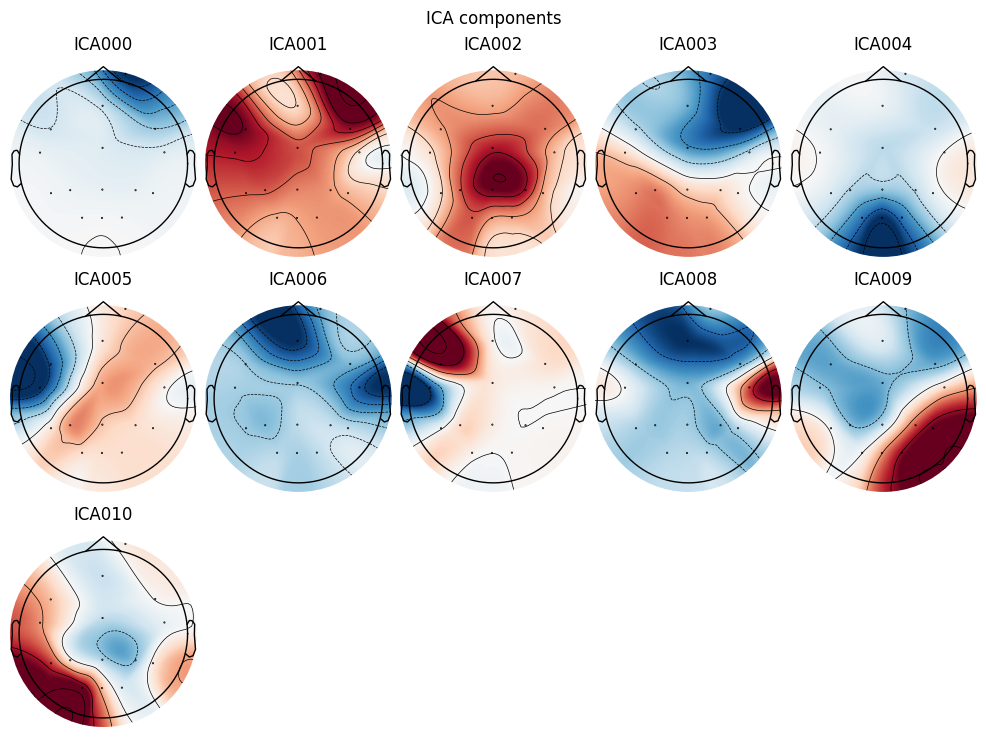

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 95.3 mm
Computing interpolation matrix from 15 sensor positions
Interpolating 1 sensors
EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.
Not setting metadata
27 matching events found
No baseline correction applied
Created an SSP operator (subspace dimension = 1)
1 projection items activated
Using data from preloaded Raw for 27 events and 2560 original time points ...
    Rejecting  epoch based on EEG : ['Fp1', 'Fp2']
    Rejecting  epoch based on EEG : ['Fp1', 'Fp2']
    Rejecting  epoch based on EEG : ['T8']
    Rejecting  epoch based on EEG : ['Fp1', 'Fp2', 'T7']
    Rejecting  epoch based on EEG : ['Fp1', 'Fp2', 'Fz', 'T7', 'T8']
    Rejecting  epoch based on EEG : ['FC5', 'T7']
    

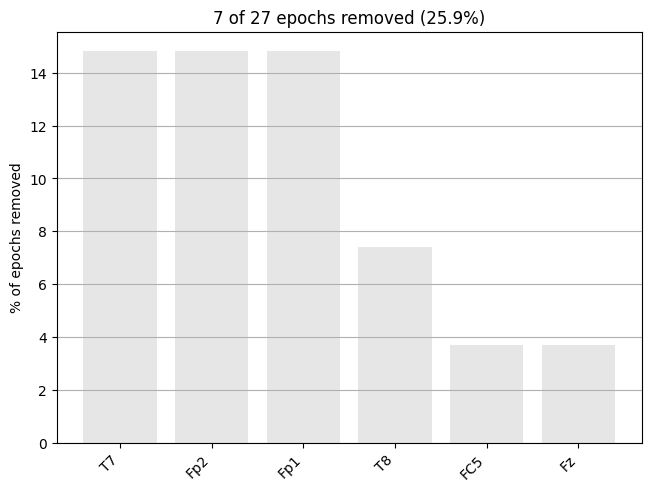

Using pyopengl with version 3.1.10
    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
Using MATLAB variable: SIGNAL
Creating RawArray with float64 data, n_channels=18, n_times=87520
    Range : 0 ... 87519 =      0.000 ...   170.936 secs
Ready.


/Users/emmaabecasis/Library/Python/3.9/lib/python/site-packages/mne/viz/utils.py:158: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Using pyopengl with version 3.1.10
Channels marked as bad:
none
Dropped 0 epochs: 
The following epochs were marked as bad and are dropped:
[]
Channels marked as bad:
none
Bad channels: []
Annotations: <Annotations | 10 segments: condition_1 (5), condition_2 (5)>
Overwriting existing file.
Writing /Users/emmaabecasis/Downloads/meditation_test_data/subject_12-annotated_raw.fif
Closing /Users/emmaabecasis/Downloads/meditation_test_data/subject_12-annotated_raw.fif
[done]
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 41 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 41.00 Hz
- Upper transition bandwidth: 10.25 Hz (-6 dB cutoff frequency: 46.12 Hz)
- F

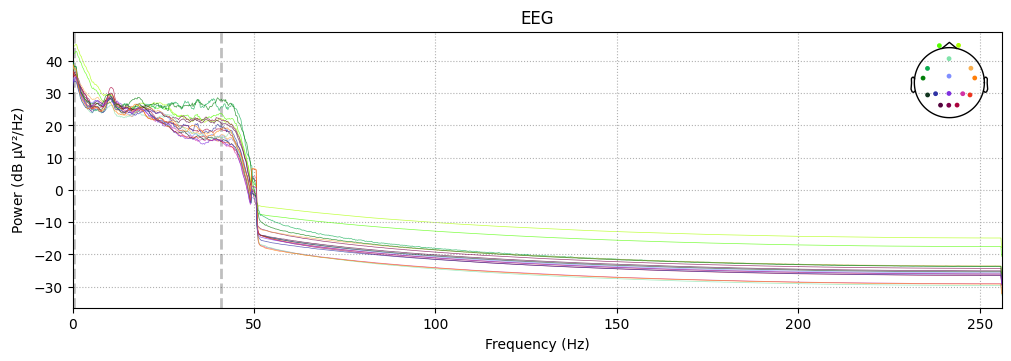

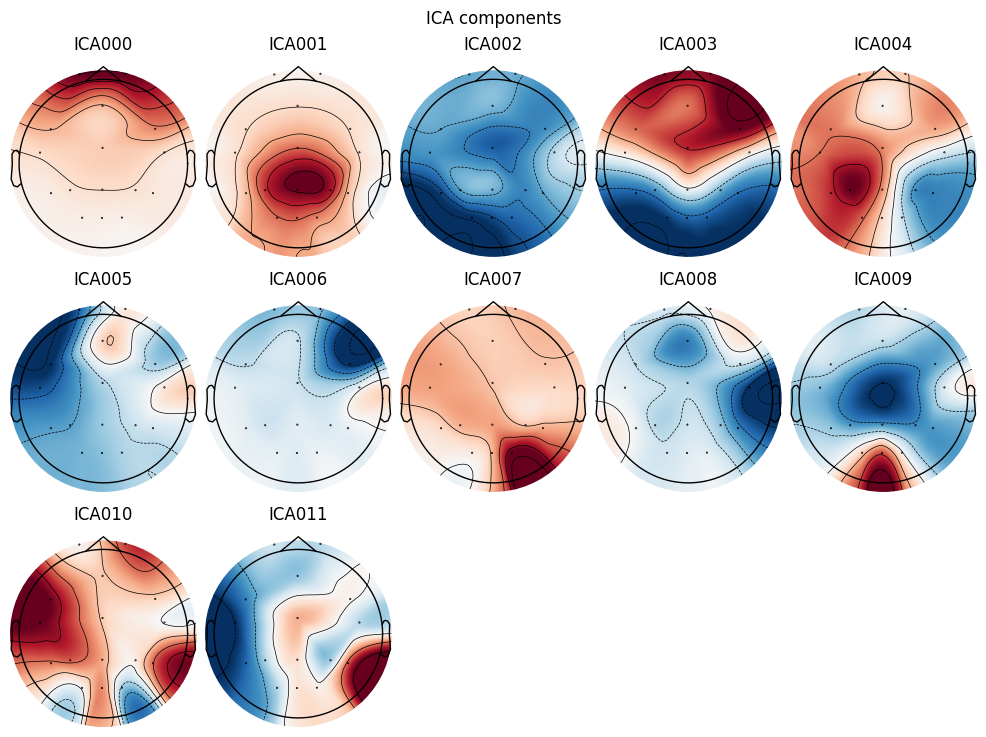

EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.
Not setting metadata
25 matching events found
No baseline correction applied
Created an SSP operator (subspace dimension = 1)
1 projection items activated
Using data from preloaded Raw for 25 events and 2560 original time points ...
    Rejecting  epoch based on EEG : ['Fp1', 'Fp2']
    Rejecting  epoch based on EEG : ['Fp1', 'Fp2']
2 bad epochs dropped

subject_12 quality summary
Original epochs: 23
Retained epochs: 23
Rejected epochs: 0
Rejected percentage: 0.0%


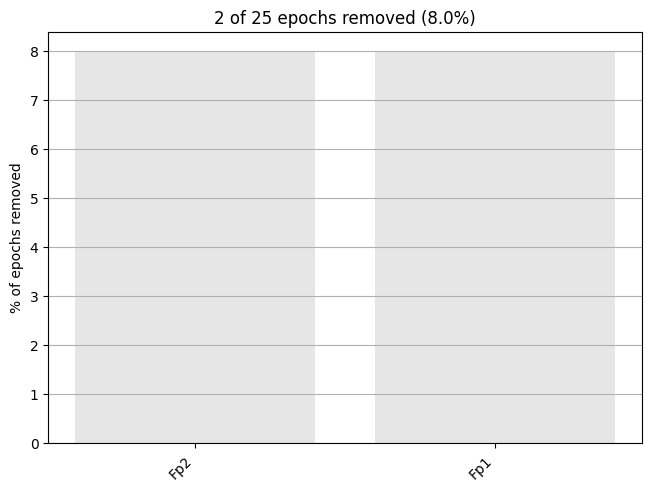

Using pyopengl with version 3.1.10
    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
Using MATLAB variable: SIGNAL
Creating RawArray with float64 data, n_channels=18, n_times=85536
    Range : 0 ... 85535 =      0.000 ...   167.061 secs
Ready.


/Users/emmaabecasis/Library/Python/3.9/lib/python/site-packages/mne/viz/utils.py:158: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Using pyopengl with version 3.1.10
Channels marked as bad:
none
Dropped 0 epochs: 
The following epochs were marked as bad and are dropped:
[]
Channels marked as bad:
none
Bad channels: []
Annotations: <Annotations | 10 segments: condition_1 (5), condition_2 (5)>
Overwriting existing file.
Writing /Users/emmaabecasis/Downloads/meditation_test_data/subject_13-annotated_raw.fif
Closing /Users/emmaabecasis/Downloads/meditation_test_data/subject_13-annotated_raw.fif
[done]
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 41 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 41.00 Hz
- Upper transition bandwidth: 10.25 Hz (-6 dB cutoff frequency: 46.12 Hz)
- F

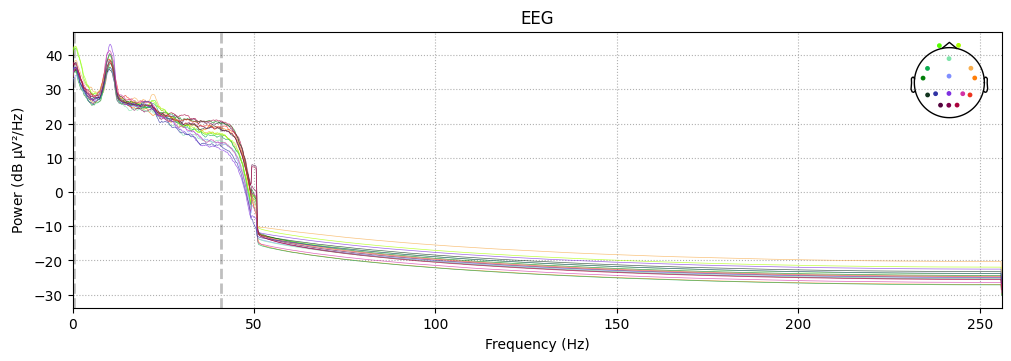

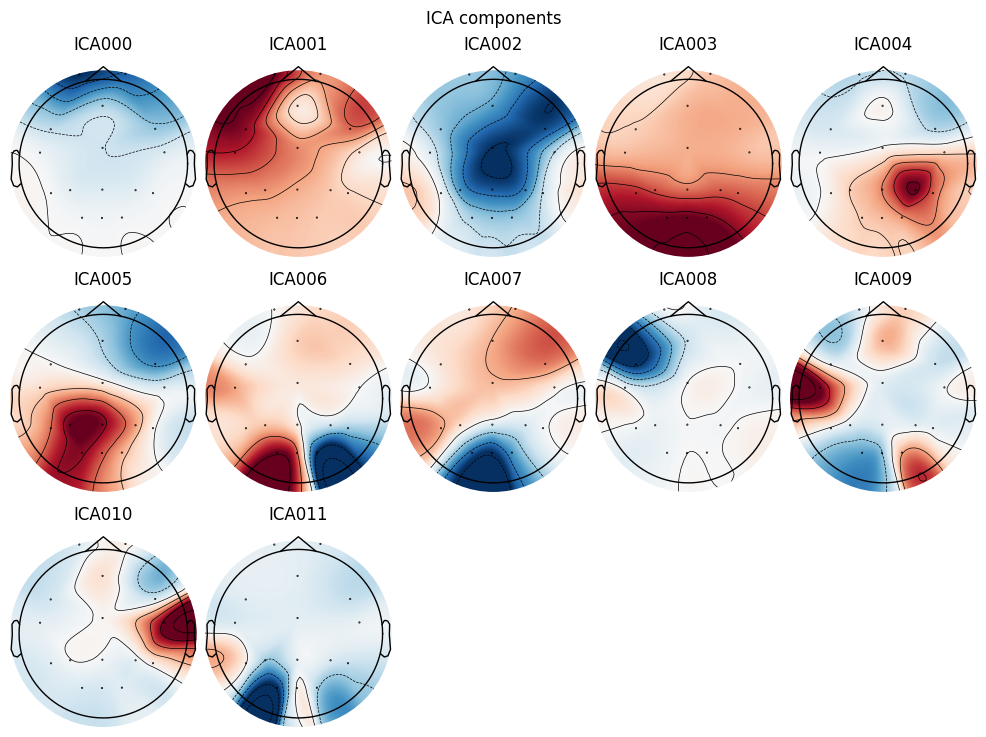

EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.
Not setting metadata
22 matching events found
No baseline correction applied
Created an SSP operator (subspace dimension = 1)
1 projection items activated
Using data from preloaded Raw for 22 events and 2560 original time points ...
    Rejecting  epoch based on EEG : ['Fp1']
1 bad epochs dropped

subject_13 quality summary
Original epochs: 21
Retained epochs: 21
Rejected epochs: 0
Rejected percentage: 0.0%


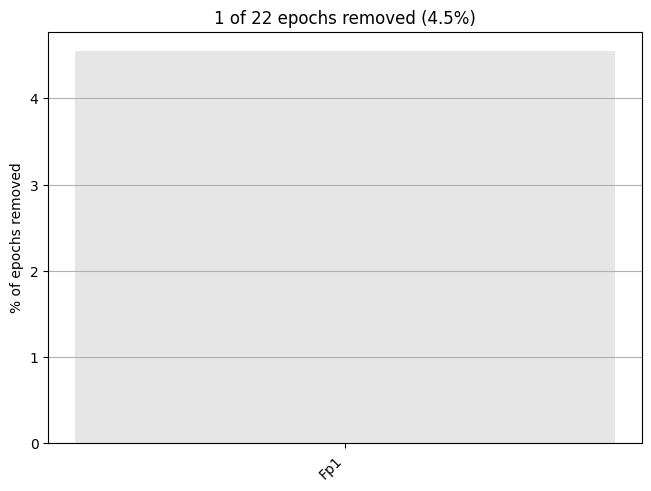

Using pyopengl with version 3.1.10
    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
Using MATLAB variable: SIGNAL
Creating RawArray with float64 data, n_channels=18, n_times=89440
    Range : 0 ... 89439 =      0.000 ...   174.686 secs
Ready.


/Users/emmaabecasis/Library/Python/3.9/lib/python/site-packages/mne/viz/utils.py:158: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Using pyopengl with version 3.1.10
Channels marked as bad:
none
Dropped 0 epochs: 
The following epochs were marked as bad and are dropped:
[]
Channels marked as bad:
none
Bad channels: []
Annotations: <Annotations | 11 segments: BAD_movement (1), condition_1 (5), condition_2 (5)>
Overwriting existing file.
Writing /Users/emmaabecasis/Downloads/meditation_test_data/subject_11-annotated_raw.fif
Closing /Users/emmaabecasis/Downloads/meditation_test_data/subject_11-annotated_raw.fif
[done]
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 41 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 41.00 Hz
- Upper transition bandwidth: 10.25 Hz (-6 dB cutoff freque

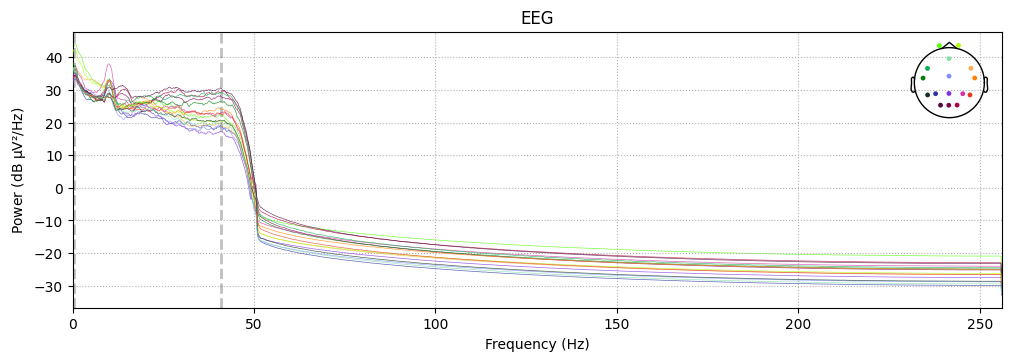

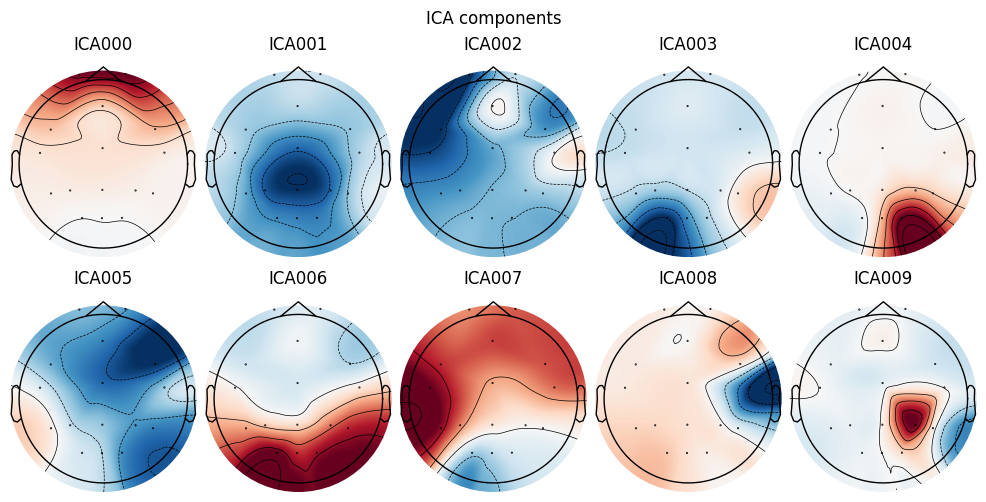

EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.
Not setting metadata
26 matching events found
No baseline correction applied
Created an SSP operator (subspace dimension = 1)
1 projection items activated
Using data from preloaded Raw for 26 events and 2560 original time points ...
    Rejecting  epoch based on EEG : ['Fp1', 'Fp2']
    Rejecting  epoch based on EEG : ['Fp1', 'Fp2']
    Rejecting  epoch based on EEG : ['Fp1', 'Fp2', 'O2']
    Rejecting  epoch based on EEG : ['Fp1', 'Fp2']
    Rejecting  epoch based on EEG : ['Fp1', 'Fp2', 'O2']
    Rejecting  epoch based on EEG : ['Fp2']
    Rejecting  epoch based on EEG : ['Fp1', 'Fp2']
7 bad epochs dropped

subject_11 quality summary
Original epochs: 19
Retained epochs: 19
Rejected epochs: 0
Rejected percentage: 0.0%


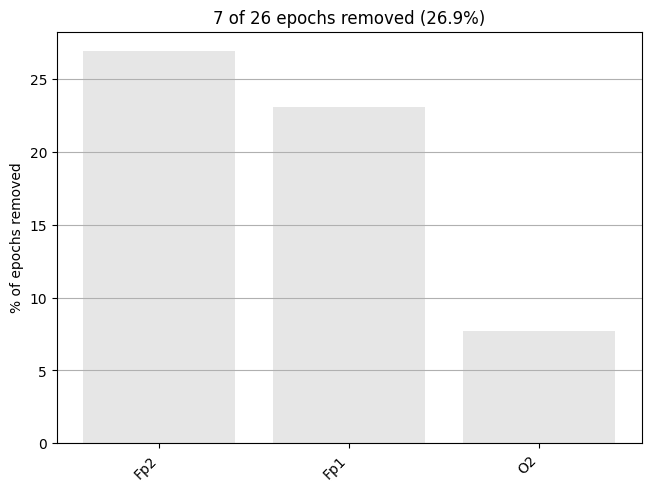

Using pyopengl with version 3.1.10
    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
Using MATLAB variable: SIGNAL
Creating RawArray with float64 data, n_channels=18, n_times=95136
    Range : 0 ... 95135 =      0.000 ...   185.811 secs
Ready.


/Users/emmaabecasis/Library/Python/3.9/lib/python/site-packages/mne/viz/utils.py:158: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Using pyopengl with version 3.1.10
Channels marked as bad:
none
Dropped 0 epochs: 
The following epochs were marked as bad and are dropped:
[]
Channels marked as bad:
none
Bad channels: []
Annotations: <Annotations | 10 segments: condition_1 (5), condition_2 (5)>
Overwriting existing file.
Writing /Users/emmaabecasis/Downloads/meditation_test_data/subject_05-annotated_raw.fif
Closing /Users/emmaabecasis/Downloads/meditation_test_data/subject_05-annotated_raw.fif
[done]
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 41 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 41.00 Hz
- Upper transition bandwidth: 10.25 Hz (-6 dB cutoff frequency: 46.12 Hz)
- F

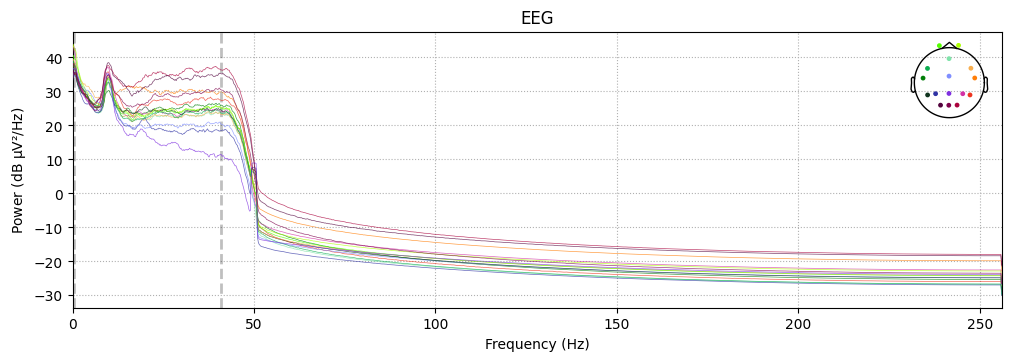

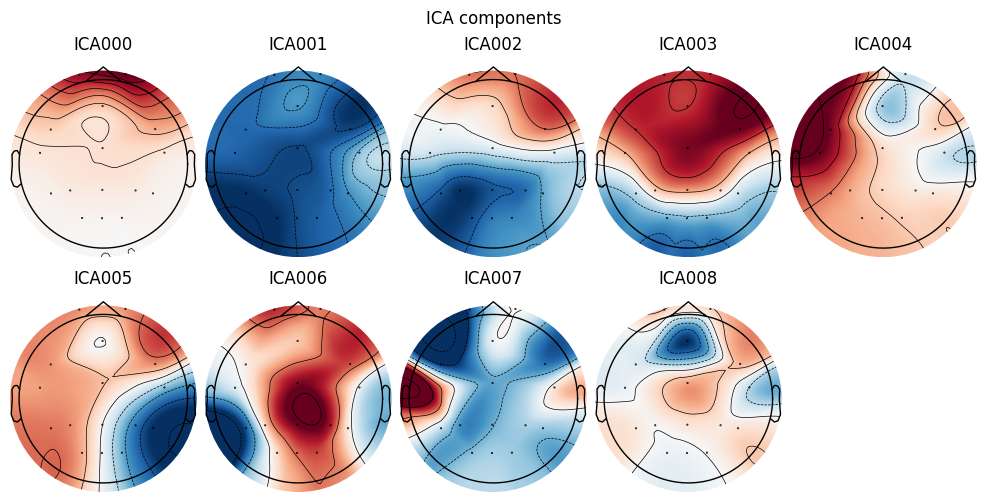

EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.
Not setting metadata
25 matching events found
No baseline correction applied
Created an SSP operator (subspace dimension = 1)
1 projection items activated
Using data from preloaded Raw for 25 events and 2560 original time points ...
    Rejecting  epoch based on EEG : ['Fp1', 'Fp2']
    Rejecting  epoch based on EEG : ['FC5', 'T7']
    Rejecting  epoch based on EEG : ['Fp1', 'Fp2']
3 bad epochs dropped

subject_05 quality summary
Original epochs: 22
Retained epochs: 22
Rejected epochs: 0
Rejected percentage: 0.0%


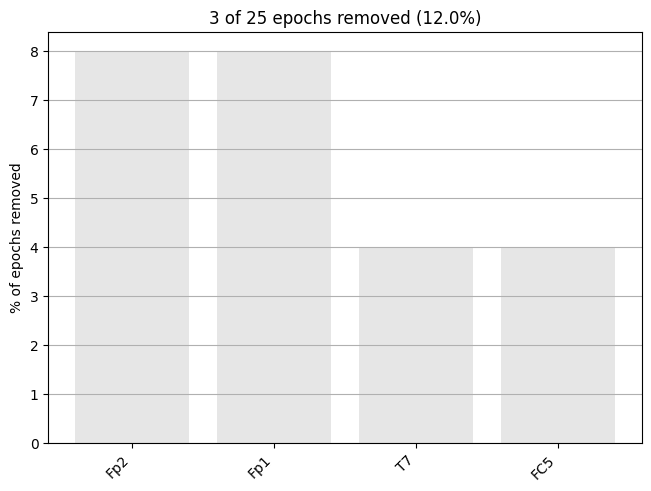

Using pyopengl with version 3.1.10
    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
Using MATLAB variable: SIGNAL
Creating RawArray with float64 data, n_channels=18, n_times=97696
    Range : 0 ... 97695 =      0.000 ...   190.811 secs
Ready.


/Users/emmaabecasis/Library/Python/3.9/lib/python/site-packages/mne/viz/utils.py:158: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Using pyopengl with version 3.1.10
Channels marked as bad:
none
Dropped 0 epochs: 
The following epochs were marked as bad and are dropped:
[]
Channels marked as bad:
none
Bad channels: []
Annotations: <Annotations | 10 segments: condition_1 (5), condition_2 (5)>
Overwriting existing file.
Writing /Users/emmaabecasis/Downloads/meditation_test_data/subject_04-annotated_raw.fif
Closing /Users/emmaabecasis/Downloads/meditation_test_data/subject_04-annotated_raw.fif
[done]
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 41 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 41.00 Hz
- Upper transition bandwidth: 10.25 Hz (-6 dB cutoff frequency: 46.12 Hz)
- F

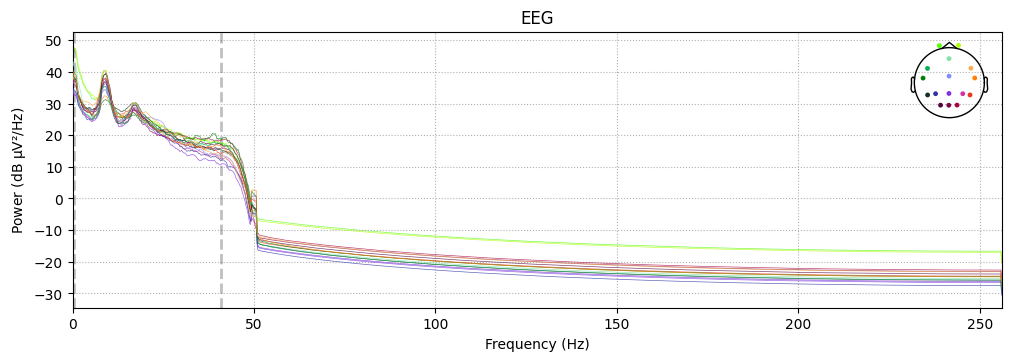

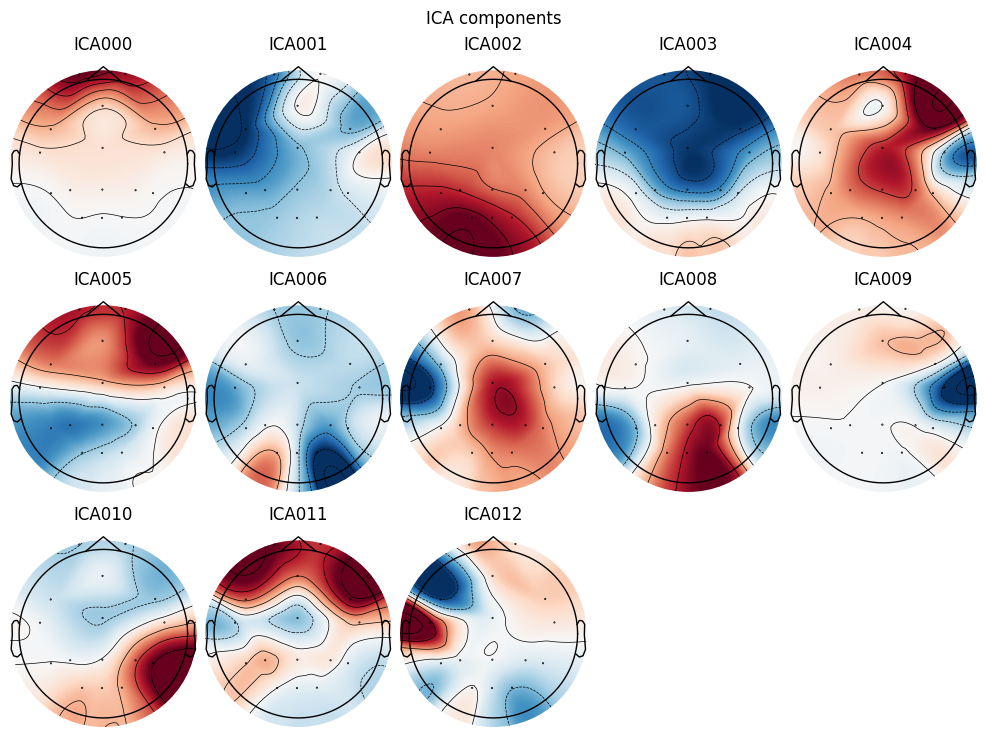

EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.
Not setting metadata
26 matching events found
No baseline correction applied
Created an SSP operator (subspace dimension = 1)
1 projection items activated
Using data from preloaded Raw for 26 events and 2560 original time points ...
    Rejecting  epoch based on EEG : ['Fp1', 'Fp2']
    Rejecting  epoch based on EEG : ['Fp1']
    Rejecting  epoch based on EEG : ['Fp1']
3 bad epochs dropped

subject_04 quality summary
Original epochs: 23
Retained epochs: 23
Rejected epochs: 0
Rejected percentage: 0.0%


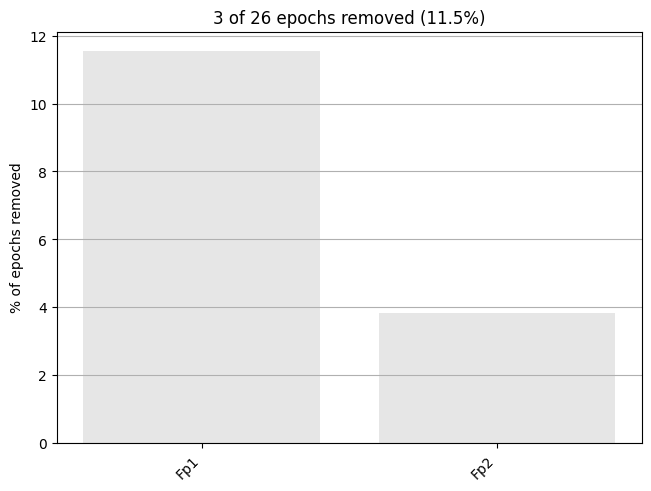

Using pyopengl with version 3.1.10
    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
Using MATLAB variable: SIGNAL
Creating RawArray with float64 data, n_channels=18, n_times=79264
    Range : 0 ... 79263 =      0.000 ...   154.811 secs
Ready.


/Users/emmaabecasis/Library/Python/3.9/lib/python/site-packages/mne/viz/utils.py:158: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Using pyopengl with version 3.1.10
Channels marked as bad:
[np.str_('T7')]
Dropped 0 epochs: 
The following epochs were marked as bad and are dropped:
[]
Channels marked as bad:
none
Bad channels: [np.str_('T7')]
Annotations: <Annotations | 10 segments: condition_1 (5), condition_2 (5)>
Overwriting existing file.
Writing /Users/emmaabecasis/Downloads/meditation_test_data/subject_10-annotated_raw.fif
Closing /Users/emmaabecasis/Downloads/meditation_test_data/subject_10-annotated_raw.fif
[done]
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 41 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 41.00 Hz
- Upper transition bandwidth: 10.25 Hz (-6 dB cutoff 

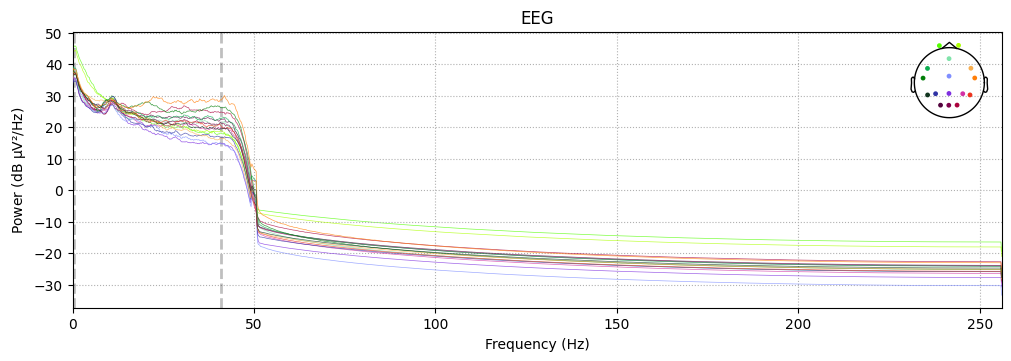

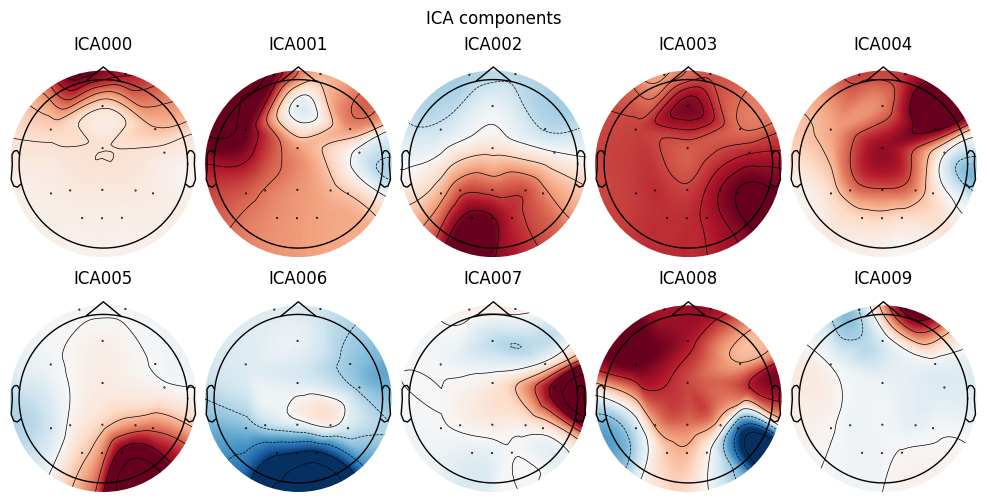

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 95.3 mm
Computing interpolation matrix from 15 sensor positions
Interpolating 1 sensors
EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.
Not setting metadata
20 matching events found
No baseline correction applied
Created an SSP operator (subspace dimension = 1)
1 projection items activated
Using data from preloaded Raw for 20 events and 2560 original time points ...
    Rejecting  epoch based on EEG : ['Fp1']
    Rejecting  epoch based on EEG : ['Fp1', 'Fp2']
    Rejecting  epoch based on EEG : ['Fp1']
3 bad epochs dropped

subject_10 quality summary
Original epochs: 17
Retained epochs: 17
Rejected epochs: 0
Rejected percentage: 0.0%


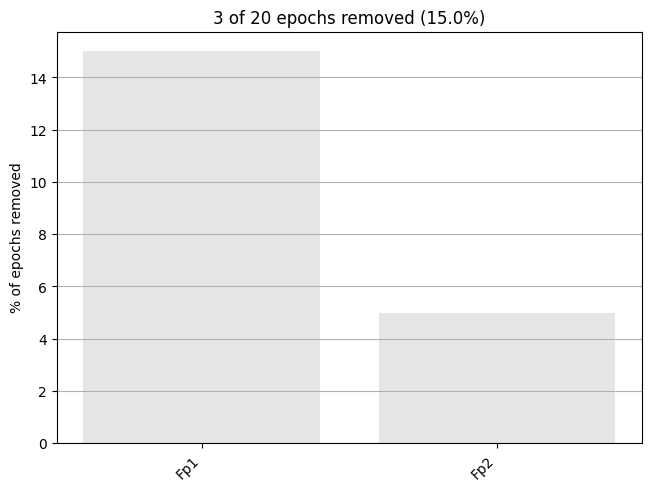

Using pyopengl with version 3.1.10
    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
Using MATLAB variable: SIGNAL
Creating RawArray with float64 data, n_channels=18, n_times=77504
    Range : 0 ... 77503 =      0.000 ...   151.373 secs
Ready.


/Users/emmaabecasis/Library/Python/3.9/lib/python/site-packages/mne/viz/utils.py:158: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Using pyopengl with version 3.1.10
Channels marked as bad:
[np.str_('P7'), np.str_('FC5')]
Dropped 0 epochs: 
The following epochs were marked as bad and are dropped:
[]
Channels marked as bad:
none
Bad channels: [np.str_('P7'), np.str_('FC5')]
Annotations: <Annotations | 10 segments: condition_1 (5), condition_2 (5)>
Overwriting existing file.
Writing /Users/emmaabecasis/Downloads/meditation_test_data/subject_14-annotated_raw.fif
Closing /Users/emmaabecasis/Downloads/meditation_test_data/subject_14-annotated_raw.fif
[done]
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 41 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 41.00 Hz
- Upper transition ba

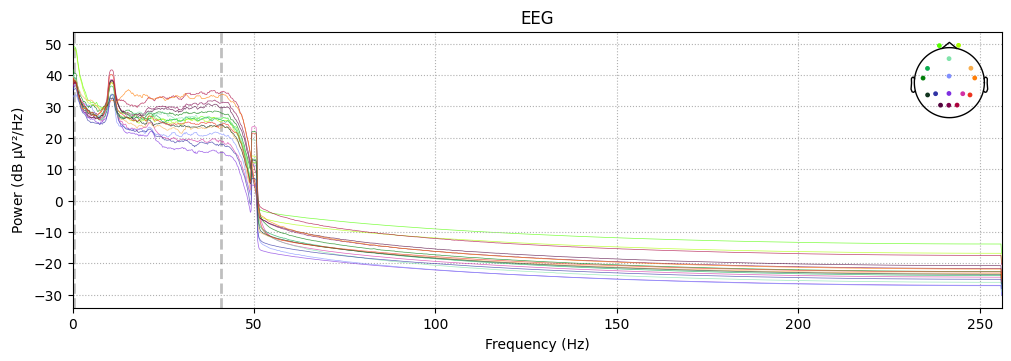

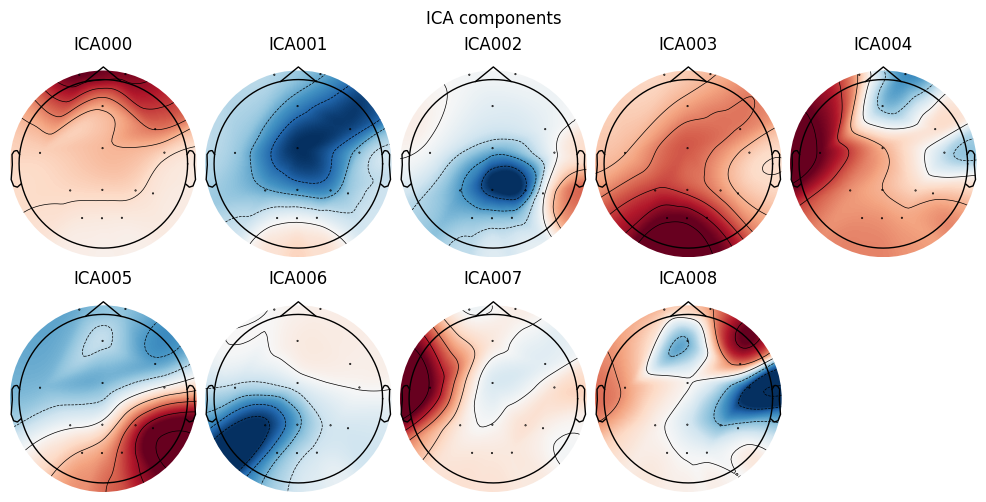

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 95.3 mm
Computing interpolation matrix from 14 sensor positions
Interpolating 2 sensors
EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.
Not setting metadata
21 matching events found
No baseline correction applied
Created an SSP operator (subspace dimension = 1)
1 projection items activated
Using data from preloaded Raw for 21 events and 2560 original time points ...
0 bad epochs dropped

subject_14 quality summary
Original epochs: 21
Retained epochs: 21
Rejected epochs: 0
Rejected percentage: 0.0%
Using pyopengl with version 3.1.10
    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
Using MAT

/Users/emmaabecasis/Library/Python/3.9/lib/python/site-packages/mne/viz/utils.py:158: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Using pyopengl with version 3.1.10
Channels marked as bad:
[np.str_('Oz'), np.str_('P7'), np.str_('FC5')]
Dropped 0 epochs: 
The following epochs were marked as bad and are dropped:
[]
Channels marked as bad:
none
Bad channels: [np.str_('Oz'), np.str_('P7'), np.str_('FC5')]
Annotations: <Annotations | 10 segments: condition_1 (5), condition_2 (5)>
Overwriting existing file.
Writing /Users/emmaabecasis/Downloads/meditation_test_data/subject_00-annotated_raw.fif
Closing /Users/emmaabecasis/Downloads/meditation_test_data/subject_00-annotated_raw.fif
[done]
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 41 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 

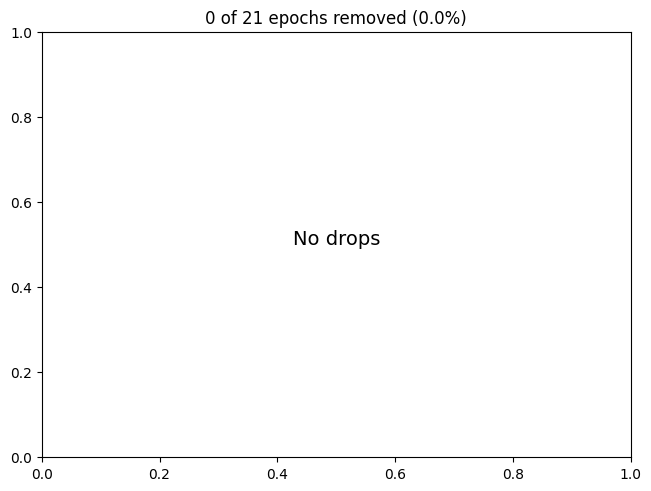

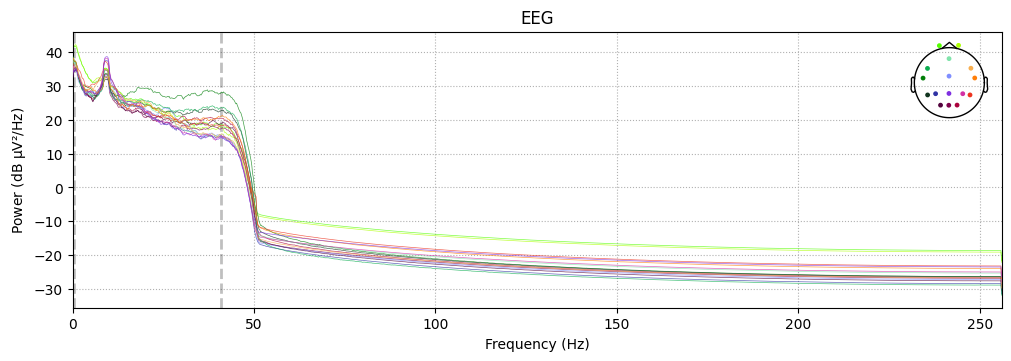

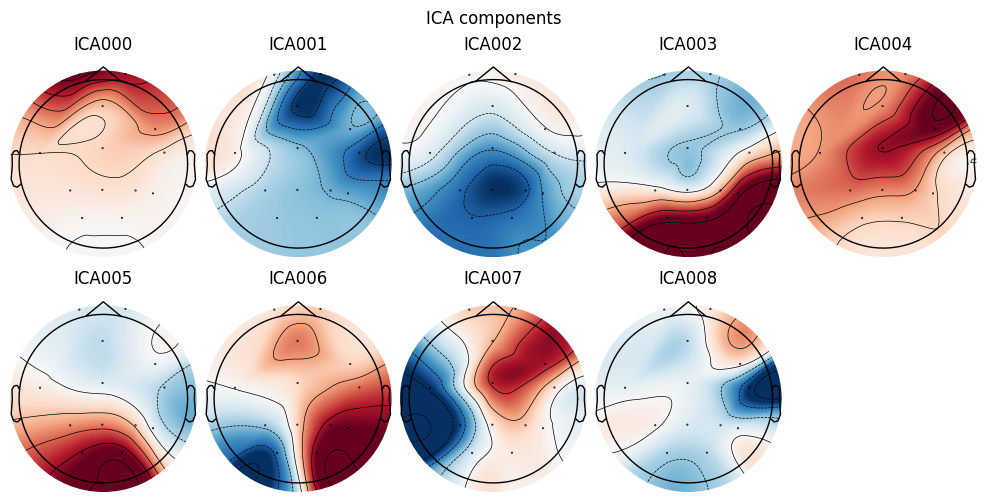

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 95.3 mm
Computing interpolation matrix from 13 sensor positions
Interpolating 3 sensors
EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.
Not setting metadata
17 matching events found
No baseline correction applied
Created an SSP operator (subspace dimension = 1)
1 projection items activated
Using data from preloaded Raw for 17 events and 2560 original time points ...
    Rejecting  epoch based on EEG : ['Fp1']
    Rejecting  epoch based on EEG : ['Fp1']
    Rejecting  epoch based on EEG : ['Fp1']
3 bad epochs dropped

subject_00 quality summary
Original epochs: 14
Retained epochs: 14
Rejected epochs: 0
Rejected percentage: 0.0%


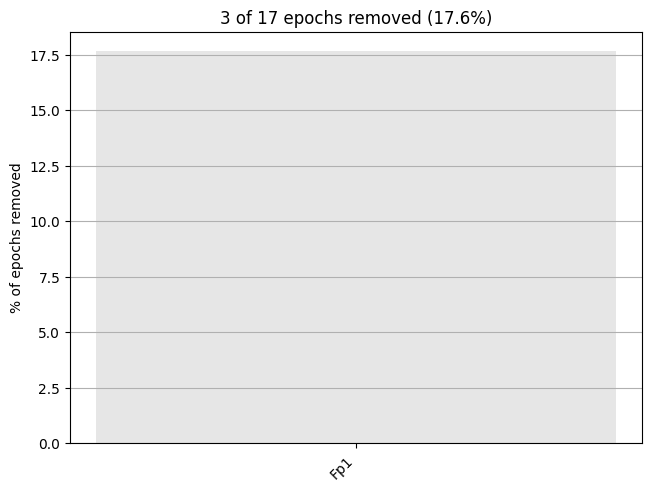

Using pyopengl with version 3.1.10
    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
Using MATLAB variable: SIGNAL
Creating RawArray with float64 data, n_channels=18, n_times=119808
    Range : 0 ... 119807 =      0.000 ...   233.998 secs
Ready.


/Users/emmaabecasis/Library/Python/3.9/lib/python/site-packages/mne/viz/utils.py:158: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


Using pyopengl with version 3.1.10
Channels marked as bad:
none
Dropped 0 epochs: 
The following epochs were marked as bad and are dropped:
[]
Channels marked as bad:
none
Bad channels: []
Annotations: <Annotations | 11 segments: BAD_drop (1), condition_1 (5), condition_2 (5)>
Overwriting existing file.
Writing /Users/emmaabecasis/Downloads/meditation_test_data/subject_01-annotated_raw.fif
Closing /Users/emmaabecasis/Downloads/meditation_test_data/subject_01-annotated_raw.fif
[done]
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 41 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 41.00 Hz
- Upper transition bandwidth: 10.25 Hz (-6 dB cutoff frequency:

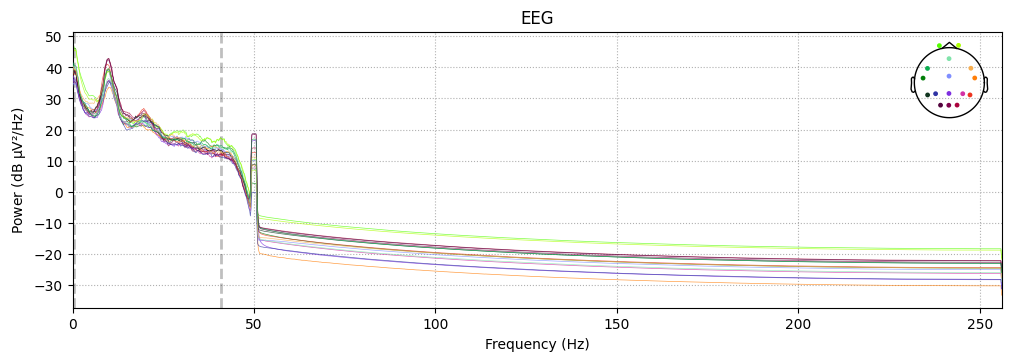

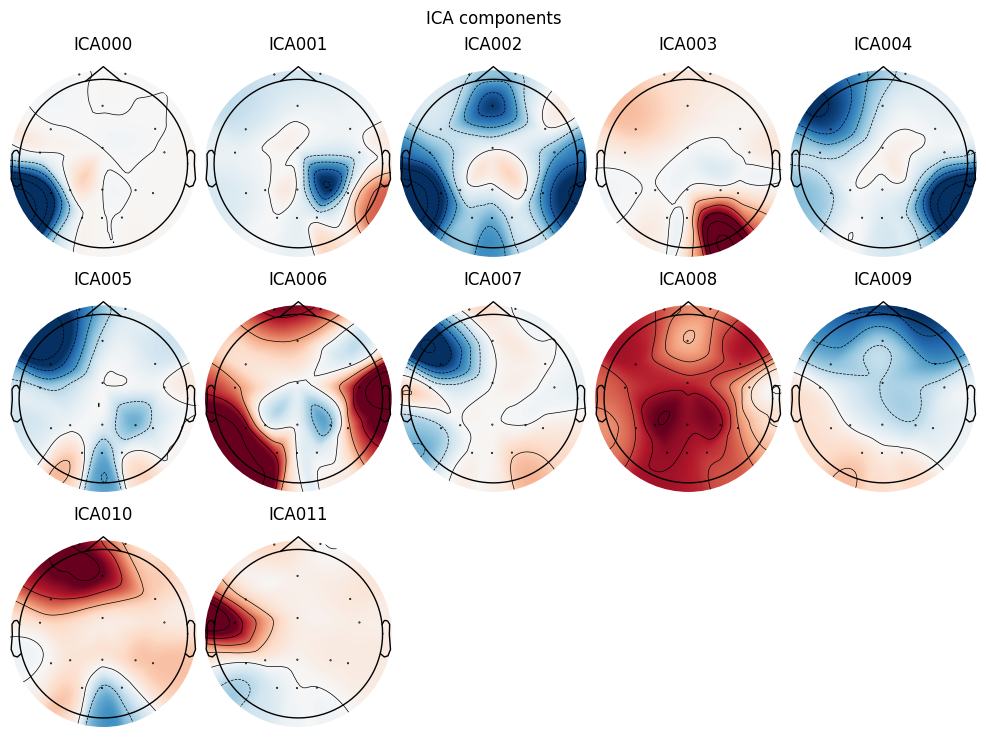

EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.
Not setting metadata
30 matching events found
No baseline correction applied
Created an SSP operator (subspace dimension = 1)
1 projection items activated
Using data from preloaded Raw for 30 events and 2560 original time points ...
    Rejecting  epoch based on EEG : ['P7']
    Rejecting  epoch based on EEG : ['P7']
    Rejecting  epoch based on EEG : ['P7']
    Rejecting  epoch based on EEG : ['P7']
    Rejecting  epoch based on EEG : ['P7']
    Rejecting  epoch based on EEG : ['P7']
    Rejecting  epoch based on EEG : ['P7']
    Rejecting  epoch based on EEG : ['FC5', 'P7', 'P4']
    Rejecting  epoch based on EEG : ['P7']
    Rejecting  epoch based on EEG : ['FC5', 'T8', 'P7', 'P4', 'P8', 'Oz']
    Rejecting  epoch based on EEG : ['Fp1', 'Fp2', 'FC5', 'FC6', 'C

/var/folders/5b/bf1nt6ln2y71xfnrhccqvn7r0000gn/T/ipykernel_60573/80195890.py:240: RuntimeWarning: All epochs were dropped!
You might need to alter reject/flat-criteria or drop bad channels to avoid this. You can use Epochs.plot_drop_log() to see which channels are responsible for the dropping of epochs.
  epochs = mne.Epochs(


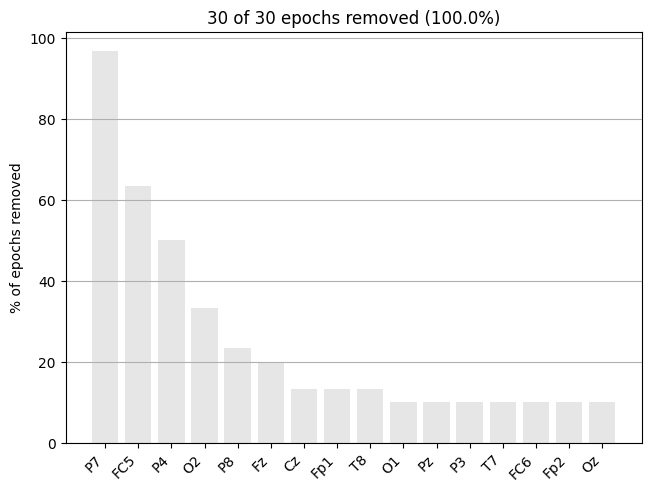

RuntimeError: epochs.plot() can't run because this Epochs-object is empty. You might want to check Epochs.drop_log or Epochs.plot_drop_log() to see why epochs were dropped.

In [9]:
# actually run code
final_data = []

for file in DATA.iterdir():
    raw, epochs, ica = process_participant(file)
    final_data.append((raw, epochs, ica))


